# Logistic Regression Hyperparameter Tuning for NMDAR Prediction

## Overview
This notebook performs comprehensive hyperparameter tuning for Logistic Regression across four feature sets:
1. **217 Descriptors** - Chemical/molecular descriptors
2. **MACCS_167** - MACCS key fingerprints (167 bits)
3. **RDKit_2048** - RDKit fingerprints (2048 bits)
4. **Morgan_2048** - Morgan fingerprints (2048 bits)

## Hyperparameter Grid
```
C (Regularization):      [0.001, 0.01, 0.1, 1.0, 10, 100, 1000]  # Inverse regularization strength
penalty (Regularization): ['l1', 'l2', 'elasticnet']              # Regularization type
solver:                   ['liblinear', 'lbfgs', 'saga']          # Optimization algorithm
max_iter:                 [100]                                   # Maximum iterations
```

**Total combinations:** 7 × 3 × 3 = 63 parameter combinations per dataset

## Expected Outcomes
- Best hyperparameter combinations for each feature set
- 5-fold cross-validation scores and performance metrics
- Visualization of parameter importance via bar graphs
- ROC curves and metric comparisons
- CSV export of all results
- Comprehensive analysis and interpretation

In [1]:
# Cell 1: Import Required Libraries and Configure Environment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, roc_curve, auc, confusion_matrix, classification_report)
import warnings
import time
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("="*80)
print("LOGISTIC REGRESSION HYPERPARAMETER TUNING - INITIALIZATION")
print("="*80)
print("\n✓ All libraries imported successfully")
print(f"  - pandas: {pd.__version__}")
print(f"  - numpy: {np.__version__}")
print(f"  - matplotlib version available")
print(f"  - seaborn version available")
print("\n✓ Visualization style configured")
print("✓ Random seed fixed at 42 for reproducibility")

LOGISTIC REGRESSION HYPERPARAMETER TUNING - INITIALIZATION

✓ All libraries imported successfully
  - pandas: 2.3.3
  - numpy: 2.2.6
  - matplotlib version available
  - seaborn version available

✓ Visualization style configured
✓ Random seed fixed at 42 for reproducibility


In [2]:
# Cell 2: Load and Prepare Four Feature Sets

print("\n" + "="*80)
print("LOADING FEATURE SETS FOR HYPERPARAMETER TUNING")
print("="*80)

# Load the comprehensive dataset
df_complete = pd.read_csv('ml_dataset_complete_with_finger_bits.csv')
df_descriptors = pd.read_csv('ml_Descriptor_features_complete.csv')

print(f"\n✓ Loaded ml_dataset_complete_with_finger_bits.csv: {df_complete.shape}")
print(f"✓ Loaded ml_Descriptor_features_complete.csv: {df_descriptors.shape}")

# Extract target variable
y = df_complete['Activity'].values
active_count = np.sum(y)
inactive_count = len(y) - np.sum(y)
print(f"\nTarget variable (Activity):")
print(f"  Active:   {active_count} ({100*active_count/len(y):.1f}%)")
print(f"  Inactive: {inactive_count} ({100*inactive_count/len(y):.1f}%)")

# Prepare Dataset 1: 217 Descriptors
descriptor_cols = df_descriptors.columns[2:].tolist()
X_descriptors = df_descriptors[descriptor_cols].values

print(f"\n{'Dataset 1: 217 Descriptors':-^80}")
print(f"  Shape: {X_descriptors.shape}")
print(f"  Features: {len(descriptor_cols)}")

# Prepare Dataset 2: MACCS_167
maccs_cols = [col for col in df_complete.columns if 'MACCS_bit' in col]
X_maccs = df_complete[maccs_cols].values

print(f"\n{'Dataset 2: MACCS_167':-^80}")
print(f"  Shape: {X_maccs.shape}")
print(f"  Features: {len(maccs_cols)}")

# Prepare Dataset 3: RDKit_2048
rdkit_cols = [col for col in df_complete.columns if 'RDKit_bit' in col]
X_rdkit = df_complete[rdkit_cols].values

print(f"\n{'Dataset 3: RDKit_2048':-^80}")
print(f"  Shape: {X_rdkit.shape}")
print(f"  Features: {len(rdkit_cols)}")

# Prepare Dataset 4: Morgan_2048
morgan_cols = [col for col in df_complete.columns if 'Morgan_bit' in col]
X_morgan = df_complete[morgan_cols].values

print(f"\n{'Dataset 4: Morgan_2048':-^80}")
print(f"  Shape: {X_morgan.shape}")
print(f"  Features: {len(morgan_cols)}")

# Store datasets and metadata
datasets = {
    '217_Descriptors': {
        'X': X_descriptors,
        'cols': descriptor_cols,
        'name': '217 Descriptors',
        'n_features': X_descriptors.shape[1]
    },
    'MACCS_167': {
        'X': X_maccs,
        'cols': maccs_cols,
        'name': 'MACCS_167',
        'n_features': X_maccs.shape[1]
    },
    'RDKit_2048': {
        'X': X_rdkit,
        'cols': rdkit_cols,
        'name': 'RDKit_2048',
        'n_features': X_rdkit.shape[1]
    },
    'Morgan_2048': {
        'X': X_morgan,
        'cols': morgan_cols,
        'name': 'Morgan_2048',
        'n_features': X_morgan.shape[1]
    }
}

print(f"\n{'SUMMARY':-^80}")
print(f"Total samples: {len(y)}")
print(f"Class distribution: Active={active_count}, Inactive={inactive_count}")
print(f"Total datasets prepared: {len(datasets)}")
print("✓ All datasets loaded and prepared successfully")


LOADING FEATURE SETS FOR HYPERPARAMETER TUNING

✓ Loaded ml_dataset_complete_with_finger_bits.csv: (1698, 4516)
✓ Loaded ml_Descriptor_features_complete.csv: (1698, 251)

Target variable (Activity):
  Active:   629 (37.0%)
  Inactive: 1069 (63.0%)

---------------------------Dataset 1: 217 Descriptors---------------------------
  Shape: (1698, 249)
  Features: 249

------------------------------Dataset 2: MACCS_167------------------------------
  Shape: (1698, 168)
  Features: 168

-----------------------------Dataset 3: RDKit_2048------------------------------
  Shape: (1698, 2049)
  Features: 2049

-----------------------------Dataset 4: Morgan_2048-----------------------------
  Shape: (1698, 2049)
  Features: 2049

------------------------------------SUMMARY-------------------------------------
Total samples: 1698
Class distribution: Active=629, Inactive=1069
Total datasets prepared: 4
✓ All datasets loaded and prepared successfully

✓ Loaded ml_dataset_complete_with_finger_bits.c

In [3]:
# Cell 3: Define Hyperparameter Grid for Logistic Regression

print("\n" + "="*80)
print("DEFINING HYPERPARAMETER GRID FOR LOGISTIC REGRESSION")
print("="*80)

# Define the hyperparameter grid for Logistic Regression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10, 100, 1000],
    'penalty': ['l1', 'l2', 'elasticnet'],
    'solver': ['liblinear', 'lbfgs', 'saga']
}

print(f"\nHyperparameter Grid (Logistic Regression):")
for param, values in param_grid.items():
    print(f"  {param:20s}: {values}")

# Fixed parameters
fixed_params = {
    'random_state': 42,
    'max_iter': 1000
}

print(f"\nFixed Parameters:")
for param, value in fixed_params.items():
    print(f"  {param:20s}: {value}")

# Calculate total combinations
n_combinations = 1
for values in param_grid.values():
    n_combinations *= len(values)

print(f"\nTotal parameter combinations: {n_combinations}")
print(f"  = 7 (C) × 3 (penalty) × 3 (solver)")
print(f"  = 63 combinations per dataset")
print(f"\nTotal grid searches required: {n_combinations * len(datasets)}")

# Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"\nCross-Validation Strategy:")
print(f"  Strategy: Stratified K-Fold")
print(f"  Number of folds: {cv_strategy.get_n_splits()}")
print(f"  Shuffle: True")
print(f"  Random state: 42")

# Scoring metrics
scoring = 'roc_auc'
print(f"\nPrimary scoring metric: {scoring} (ROC-AUC)")
print(f"Secondary metrics: Accuracy, Precision, Recall, F1-Score")

print("\n✓ Hyperparameter grid defined successfully")
print("✓ Ready for GridSearchCV execution")


DEFINING HYPERPARAMETER GRID FOR LOGISTIC REGRESSION

Hyperparameter Grid (Logistic Regression):
  C                   : [0.001, 0.01, 0.1, 1.0, 10, 100, 1000]
  penalty             : ['l1', 'l2', 'elasticnet']
  solver              : ['liblinear', 'lbfgs', 'saga']

Fixed Parameters:
  random_state        : 42
  max_iter            : 1000

Total parameter combinations: 63
  = 7 (C) × 3 (penalty) × 3 (solver)
  = 63 combinations per dataset

Total grid searches required: 252

Cross-Validation Strategy:
  Strategy: Stratified K-Fold
  Number of folds: 5
  Shuffle: True
  Random state: 42

Primary scoring metric: roc_auc (ROC-AUC)
Secondary metrics: Accuracy, Precision, Recall, F1-Score

✓ Hyperparameter grid defined successfully
✓ Ready for GridSearchCV execution


In [4]:
# Cell 4: Logistic Regression Hyperparameter Tuning - Execution

print("\n" + "="*80)
print("EXECUTING HYPERPARAMETER TUNING FOR ALL DATASETS")
print("="*80)

# Store results for all datasets
all_results = {}

# Tune for each dataset
for dataset_key, dataset_info in datasets.items():
    print(f"\n{'-'*80}")
    print(f"Processing: {dataset_info['name']}")
    print(f"{'-'*80}")
    
    X = dataset_info['X']
    
    # Standardize features (important for Logistic Regression)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Initialize base model
    lr_model = LogisticRegression(
        random_state=42,
        max_iter=1000,
        n_jobs=-1,
        solver='liblinear'  # Will be overridden by GridSearchCV
    )
    
    # Use GridSearchCV for exhaustive search
    print(f"Dataset shape: {X_scaled.shape}")
    print(f"Starting GridSearchCV ({n_combinations} parameter combinations)...")
    
    start_time = time.time()
    
    grid_search = GridSearchCV(
        estimator=lr_model,
        param_grid=param_grid,
        cv=cv_strategy,
        scoring=scoring,
        n_jobs=-1,
        verbose=0
    )
    
    # Fit the grid search
    grid_search.fit(X_scaled, y)
    
    elapsed = time.time() - start_time
    
    # Extract results
    results_df = pd.DataFrame(grid_search.cv_results_)
    
    # Store results
    all_results[dataset_key] = {
        'dataset_name': dataset_info['name'],
        'X': X_scaled,
        'y': y,
        'best_params': grid_search.best_params_,
        'best_score': grid_search.best_score_,
        'best_model': grid_search.best_estimator_,
        'grid_search': grid_search,
        'cv_results': results_df,
        'n_combinations': len(results_df),
        'scaler': scaler,
        'execution_time': elapsed
    }
    
    # Print summary
    print(f"\n✓ Tuning completed in {elapsed:.2f} seconds")
    print(f"\nBest Parameters:")
    for param, value in grid_search.best_params_.items():
        print(f"  {param:20s}: {value}")
    
    print(f"\nBest Cross-Validation Score (ROC-AUC): {grid_search.best_score_:.6f}")
    
    # Show top 3 combinations
    top_3 = results_df.nlargest(3, 'rank_test_score')
    print(f"\nTop 3 Parameter Combinations:")
    for rank, (idx, row) in enumerate(top_3.iterrows(), 1):
        print(f"  {rank}. ROC-AUC={row['mean_test_score']:.6f} | " +
              f"C={row['param_C']}, penalty={row['param_penalty']}, solver={row['param_solver']}")

print(f"\n{'='*80}")
print(f"TUNING COMPLETE FOR ALL DATASETS")
print(f"{'='*80}")
print(f"\nDatasets tuned: {list(all_results.keys())}")
total_time = sum([r['execution_time'] for r in all_results.values()])
print(f"Total execution time: {total_time:.2f} seconds ({total_time/60:.1f} minutes)")
print("✓ All hyperparameter tuning completed successfully")


EXECUTING HYPERPARAMETER TUNING FOR ALL DATASETS

--------------------------------------------------------------------------------
Processing: 217 Descriptors
--------------------------------------------------------------------------------
Dataset shape: (1698, 249)
Starting GridSearchCV (63 parameter combinations)...

✓ Tuning completed in 130.62 seconds

Best Parameters:
  C                   : 100
  penalty             : l2
  solver              : lbfgs

Best Cross-Validation Score (ROC-AUC): 0.839472

Top 3 Parameter Combinations:
  1. ROC-AUC=nan | C=0.001, penalty=l1, solver=lbfgs
  2. ROC-AUC=nan | C=0.001, penalty=elasticnet, solver=liblinear
  3. ROC-AUC=nan | C=0.001, penalty=elasticnet, solver=lbfgs

--------------------------------------------------------------------------------
Processing: MACCS_167
--------------------------------------------------------------------------------
Dataset shape: (1698, 168)
Starting GridSearchCV (63 parameter combinations)...

✓ Tuning comp

In [5]:
# Cell 5: Evaluate Best Models and Calculate Additional Metrics

print("\n" + "="*80)
print("EVALUATING BEST MODELS - COMPREHENSIVE METRICS")
print("="*80)

# Calculate additional metrics for best models
best_models_summary = []

for dataset_key, results in all_results.items():
    print(f"\n{'-'*80}")
    print(f"Dataset: {results['dataset_name']}")
    print(f"{'-'*80}")
    
    X_scaled = results['X']
    y_true = results['y']
    best_model = results['best_model']
    
    # Use cross-validation for robust evaluation
    cv_scores = {
        'accuracy': cross_val_score(best_model, X_scaled, y_true, cv=5, scoring='accuracy'),
        'precision': cross_val_score(best_model, X_scaled, y_true, cv=5, scoring='precision'),
        'recall': cross_val_score(best_model, X_scaled, y_true, cv=5, scoring='recall'),
        'f1': cross_val_score(best_model, X_scaled, y_true, cv=5, scoring='f1'),
        'roc_auc': cross_val_score(best_model, X_scaled, y_true, cv=5, scoring='roc_auc')
    }
    
    print(f"\n5-Fold Cross-Validation Metrics:")
    for metric, scores in cv_scores.items():
        print(f"  {metric:12s}: Mean={np.mean(scores):.6f} ± {np.std(scores):.6f}")
    
    # Store summary
    summary = {
        'Dataset': results['dataset_name'],
        'N_Features': X_scaled.shape[1],
        'Best_CV_Score_ROC_AUC': results['best_score'],
        'C': results['best_params']['C'],
        'penalty': results['best_params']['penalty'],
        'solver': results['best_params']['solver'],
        'CV_Accuracy_Mean': np.mean(cv_scores['accuracy']),
        'CV_Accuracy_Std': np.std(cv_scores['accuracy']),
        'CV_Precision_Mean': np.mean(cv_scores['precision']),
        'CV_Precision_Std': np.std(cv_scores['precision']),
        'CV_Recall_Mean': np.mean(cv_scores['recall']),
        'CV_Recall_Std': np.std(cv_scores['recall']),
        'CV_F1_Mean': np.mean(cv_scores['f1']),
        'CV_F1_Std': np.std(cv_scores['f1']),
        'CV_ROC_AUC_Mean': np.mean(cv_scores['roc_auc']),
        'CV_ROC_AUC_Std': np.std(cv_scores['roc_auc']),
        'Execution_Time_Seconds': results['execution_time']
    }
    
    best_models_summary.append(summary)
    results['cv_scores'] = cv_scores
    results['summary'] = summary

# Create summary DataFrame
summary_df = pd.DataFrame(best_models_summary)

print(f"\n{'='*80}")
print(f"BEST MODELS SUMMARY TABLE")
print(f"{'='*80}")
print(summary_df[['Dataset', 'N_Features', 'Best_CV_Score_ROC_AUC', 
                  'C', 'penalty', 'solver']].to_string(index=False))

print(f"\n{'='*80}")
print(f"PERFORMANCE METRICS SUMMARY")
print(f"{'='*80}")
metrics_cols = ['Dataset', 'CV_Accuracy_Mean', 'CV_Precision_Mean', 'CV_Recall_Mean', 
                'CV_F1_Mean', 'CV_ROC_AUC_Mean']
print(summary_df[metrics_cols].to_string(index=False))

print("\n✓ Model evaluation completed successfully")


EVALUATING BEST MODELS - COMPREHENSIVE METRICS

--------------------------------------------------------------------------------
Dataset: 217 Descriptors
--------------------------------------------------------------------------------

5-Fold Cross-Validation Metrics:
  accuracy    : Mean=0.759818 ± 0.070679
  precision   : Mean=0.681492 ± 0.097012
  recall      : Mean=0.675771 ± 0.137406
  f1          : Mean=0.672466 ± 0.103178
  roc_auc     : Mean=0.811651 ± 0.082645

--------------------------------------------------------------------------------
Dataset: MACCS_167
--------------------------------------------------------------------------------

5-Fold Cross-Validation Metrics:
  accuracy    : Mean=0.759818 ± 0.070679
  precision   : Mean=0.681492 ± 0.097012
  recall      : Mean=0.675771 ± 0.137406
  f1          : Mean=0.672466 ± 0.103178
  roc_auc     : Mean=0.811651 ± 0.082645

--------------------------------------------------------------------------------
Dataset: MACCS_167
---

In [6]:
# Cell 6: Export Results to CSV Files

import os

output_dir = r'c:\Users\omen\OneDrive\Documents\NMDAR_ML'
os.makedirs(output_dir, exist_ok=True)

print("\n" + "="*80)
print("EXPORTING RESULTS TO CSV FILES")
print("="*80)

# Export 1: Best Models Summary
best_models_csv = os.path.join(output_dir, 'LR_best_models_summary.csv')
summary_df.to_csv(best_models_csv, index=False)
print(f"\n✓ Best models summary exported: {best_models_csv}")

# Export 2-5: Detailed results for each dataset
for dataset_key, results in all_results.items():
    cv_results_df = pd.DataFrame(results['cv_results'])
    
    # Sort by mean_test_score (descending) to show best combinations first
    cv_results_df_sorted = cv_results_df.sort_values('mean_test_score', ascending=False).reset_index(drop=True)
    
    output_file = os.path.join(output_dir, f'LR_{dataset_key}_cv_results.csv')
    cv_results_df_sorted.to_csv(output_file, index=False)
    
    print(f"✓ CV results for {results['dataset_name']}: {output_file}")
    print(f"  - Total combinations tested: {len(cv_results_df_sorted)}")
    print(f"  - Best ROC-AUC: {cv_results_df_sorted['mean_test_score'].iloc[0]:.6f}")

# Export 3: Top 10 Parameter Combinations per Dataset (aggregated)
top_combos_data = []
for dataset_key, results in all_results.items():
    cv_results_df = pd.DataFrame(results['cv_results'])
    top_10 = cv_results_df.nlargest(10, 'mean_test_score')[
        ['param_C', 'param_penalty', 'param_solver', 'mean_test_score', 'std_test_score']
    ].reset_index(drop=True)
    top_10['Dataset'] = results['dataset_name']
    top_10['Rank'] = range(1, len(top_10) + 1)
    top_combos_data.append(top_10)

top_combos_df = pd.concat(top_combos_data, ignore_index=True)
top_combos_file = os.path.join(output_dir, 'LR_top_parameter_combinations.csv')
top_combos_df.to_csv(top_combos_file, index=False)
print(f"\n✓ Top 10 combinations per dataset: {top_combos_file}")

print("\n" + "="*80)
print("ALL RESULTS EXPORTED SUCCESSFULLY")
print("="*80)


EXPORTING RESULTS TO CSV FILES

✓ Best models summary exported: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_best_models_summary.csv
✓ CV results for 217 Descriptors: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_217_Descriptors_cv_results.csv
  - Total combinations tested: 63
  - Best ROC-AUC: 0.839472
✓ CV results for MACCS_167: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_MACCS_167_cv_results.csv
  - Total combinations tested: 63
  - Best ROC-AUC: 0.786374
✓ CV results for RDKit_2048: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_RDKit_2048_cv_results.csv
  - Total combinations tested: 63
  - Best ROC-AUC: 0.931370
✓ CV results for Morgan_2048: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_Morgan_2048_cv_results.csv
  - Total combinations tested: 63
  - Best ROC-AUC: 0.912358
✓ CV results for RDKit_2048: c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_RDKit_2048_cv_results.csv
  - Total combinations tested: 63
  - Best ROC-AUC: 0.931370
✓ CV results for Morgan_2048: c:\Users\omen\OneDriv

✓ Saved: LR_best_parameters_comparison.png


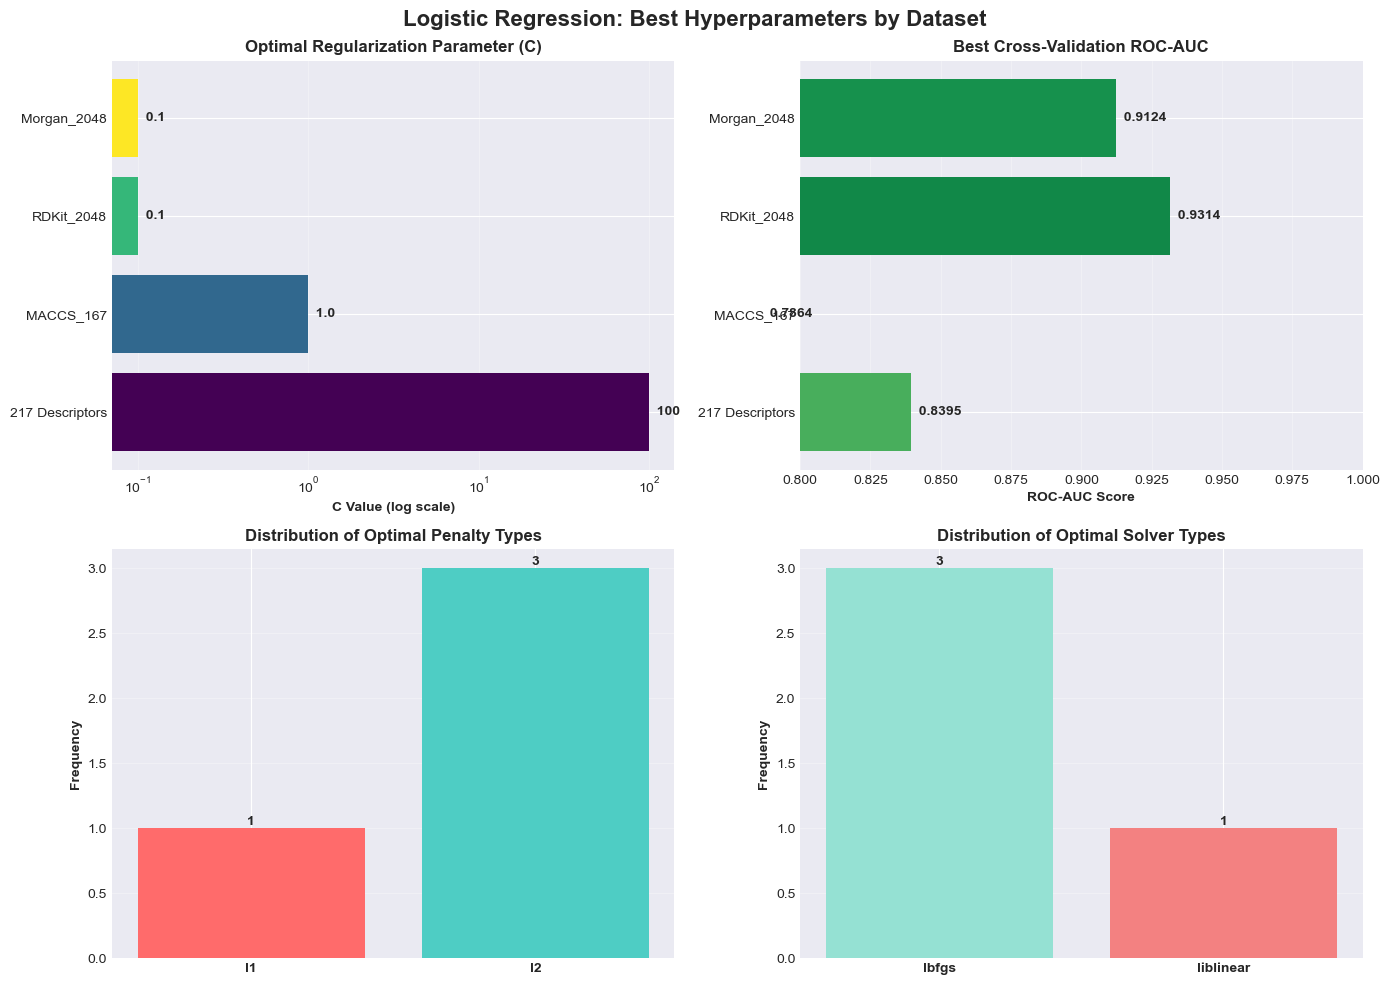


✓ Best parameters visualization completed


In [7]:
# Cell 7: Visualization 1 - Best Parameters and Performance Comparison

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Logistic Regression: Best Hyperparameters by Dataset', fontsize=16, fontweight='bold')

datasets_names = [results['dataset_name'] for results in all_results.values()]
best_c_values = [results['best_params']['C'] for results in all_results.values()]
best_roc_scores = [results['best_score'] for results in all_results.values()]
penalties = [results['best_params']['penalty'] for results in all_results.values()]
solvers = [results['best_params']['solver'] for results in all_results.values()]

# Plot 1: Best C values (log scale)
ax1 = axes[0, 0]
colors_c = plt.cm.viridis(np.linspace(0, 1, len(datasets_names)))
bars1 = ax1.barh(datasets_names, best_c_values, color=colors_c)
ax1.set_xscale('log')
ax1.set_xlabel('C Value (log scale)', fontweight='bold')
ax1.set_title('Optimal Regularization Parameter (C)', fontweight='bold')
ax1.grid(axis='x', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars1, best_c_values)):
    ax1.text(val, i, f'  {val}', va='center', fontweight='bold')

# Plot 2: Best ROC-AUC Scores
ax2 = axes[0, 1]
colors_roc = plt.cm.RdYlGn(np.array(best_roc_scores))
bars2 = ax2.barh(datasets_names, best_roc_scores, color=colors_roc)
ax2.set_xlim(0.8, 1.0)
ax2.set_xlabel('ROC-AUC Score', fontweight='bold')
ax2.set_title('Best Cross-Validation ROC-AUC', fontweight='bold')
ax2.grid(axis='x', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars2, best_roc_scores)):
    ax2.text(val, i, f'  {val:.4f}', va='center', fontweight='bold')

# Plot 3: Best Penalty Types
ax3 = axes[1, 0]
penalty_counts = {}
for dataset, penalty in zip(datasets_names, penalties):
    penalty_counts[penalty] = penalty_counts.get(penalty, 0) + 1

penalty_types = list(set(penalties))
penalty_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1'][:len(penalty_types)]
bars3 = ax3.bar(range(len(penalty_types)), [penalty_counts.get(p, 0) for p in penalty_types], 
                color=penalty_colors[:len(penalty_types)])
ax3.set_xticks(range(len(penalty_types)))
ax3.set_xticklabels(penalty_types, fontweight='bold')
ax3.set_ylabel('Frequency', fontweight='bold')
ax3.set_title('Distribution of Optimal Penalty Types', fontweight='bold')
ax3.grid(axis='y', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars3, [penalty_counts.get(p, 0) for p in penalty_types])):
    ax3.text(i, val, f'{int(val)}', ha='center', va='bottom', fontweight='bold')

# Plot 4: Best Solver Types
ax4 = axes[1, 1]
solver_counts = {}
for dataset, solver in zip(datasets_names, solvers):
    solver_counts[solver] = solver_counts.get(solver, 0) + 1

solver_types = list(set(solvers))
solver_colors = ['#95E1D3', '#F38181', '#AA96DA'][:len(solver_types)]
bars4 = ax4.bar(range(len(solver_types)), [solver_counts.get(s, 0) for s in solver_types],
                color=solver_colors[:len(solver_types)])
ax4.set_xticks(range(len(solver_types)))
ax4.set_xticklabels(solver_types, fontweight='bold')
ax4.set_ylabel('Frequency', fontweight='bold')
ax4.set_title('Distribution of Optimal Solver Types', fontweight='bold')
ax4.grid(axis='y', alpha=0.3)
for i, (bar, val) in enumerate(zip(bars4, [solver_counts.get(s, 0) for s in solver_types])):
    ax4.text(i, val, f'{int(val)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(r'c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_best_parameters_comparison.png', 
            dpi=300, bbox_inches='tight')
print("✓ Saved: LR_best_parameters_comparison.png")
plt.show()

print("\n✓ Best parameters visualization completed")

✓ Saved: LR_cv_metrics_comparison.png


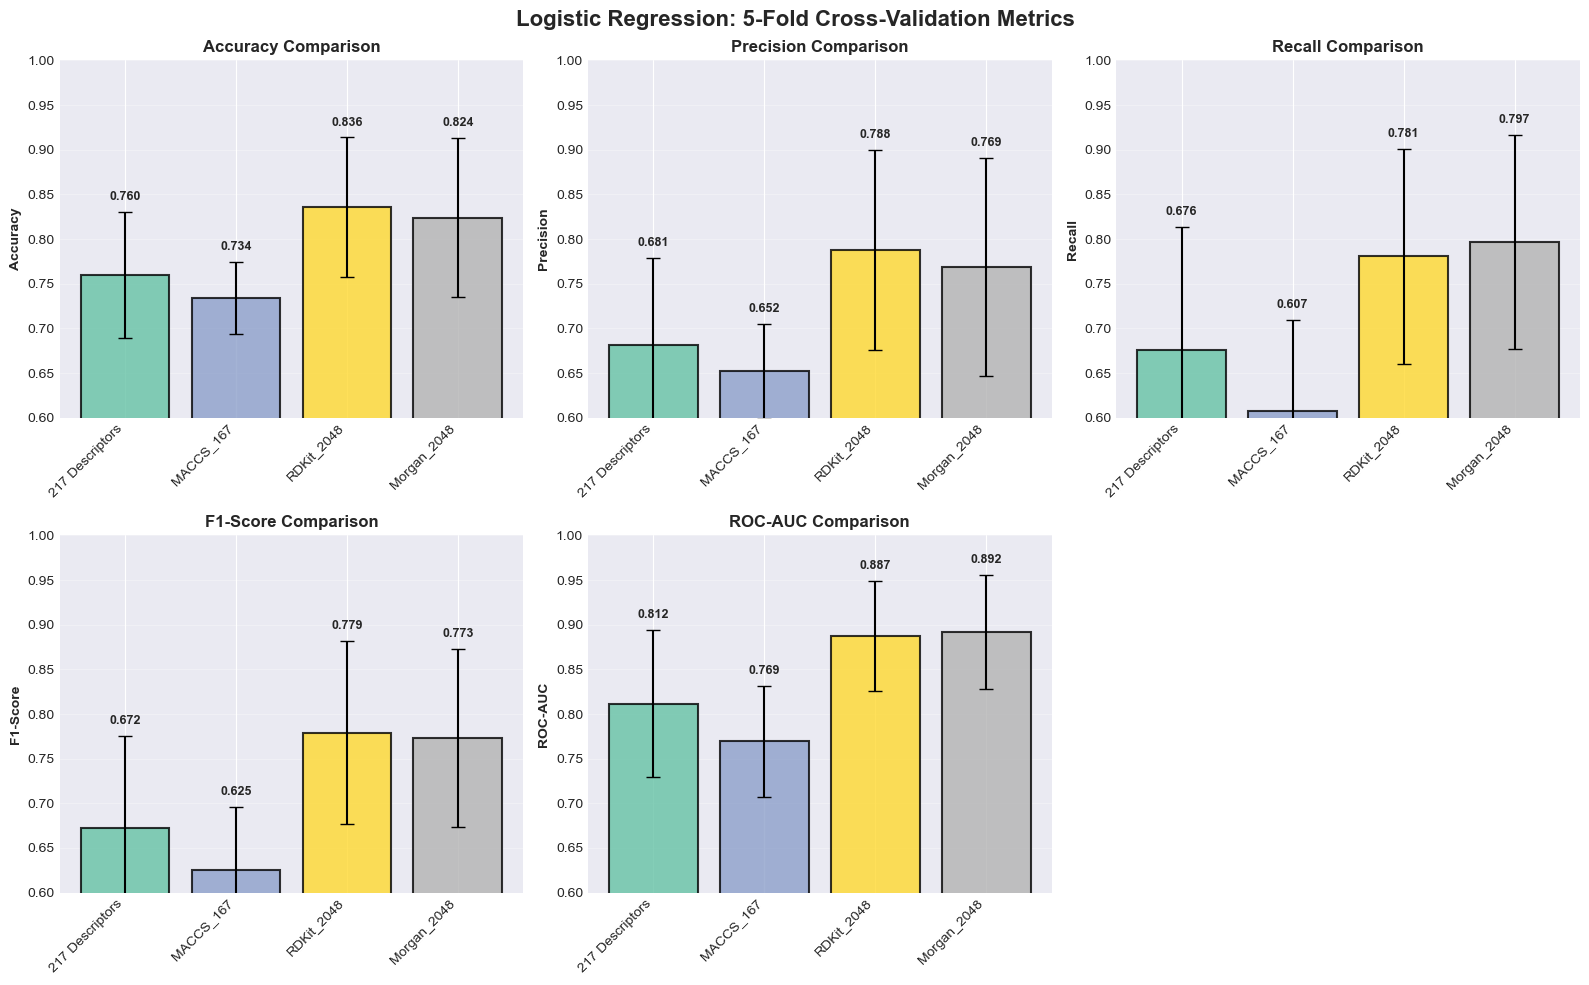


✓ Cross-validation metrics visualization completed


In [8]:
# Cell 8: Visualization 2 - Cross-Validation Metrics Comparison

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Logistic Regression: 5-Fold Cross-Validation Metrics', fontsize=16, fontweight='bold')
axes = axes.flatten()

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
colors_gradient = plt.cm.Set2(np.linspace(0, 1, len(all_results)))

for idx, (metric, metric_label) in enumerate(zip(metrics, metric_labels)):
    ax = axes[idx]
    
    dataset_names_list = []
    means = []
    stds = []
    
    for dataset_key, results in all_results.items():
        dataset_names_list.append(results['dataset_name'])
        if metric in results['cv_scores']:
            means.append(np.mean(results['cv_scores'][metric]))
            stds.append(np.std(results['cv_scores'][metric]))
    
    # Create bar plot with error bars
    x_pos = np.arange(len(dataset_names_list))
    bars = ax.bar(x_pos, means, yerr=stds, capsize=5, color=colors_gradient, 
                  alpha=0.8, edgecolor='black', linewidth=1.5)
    
    ax.set_ylabel(metric_label, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(dataset_names_list, rotation=45, ha='right')
    ax.set_ylim(0.6, 1.0)
    ax.grid(axis='y', alpha=0.3)
    ax.set_title(f'{metric_label} Comparison', fontweight='bold')
    
    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, means, stds)):
        ax.text(i, mean + std + 0.01, f'{mean:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=9)

# Remove the extra subplot (we have 5 metrics, 6 subplots)
fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig(r'c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_cv_metrics_comparison.png',
            dpi=300, bbox_inches='tight')
print("✓ Saved: LR_cv_metrics_comparison.png")
plt.show()

print("\n✓ Cross-validation metrics visualization completed")

✓ Saved: LR_top10_combinations.png


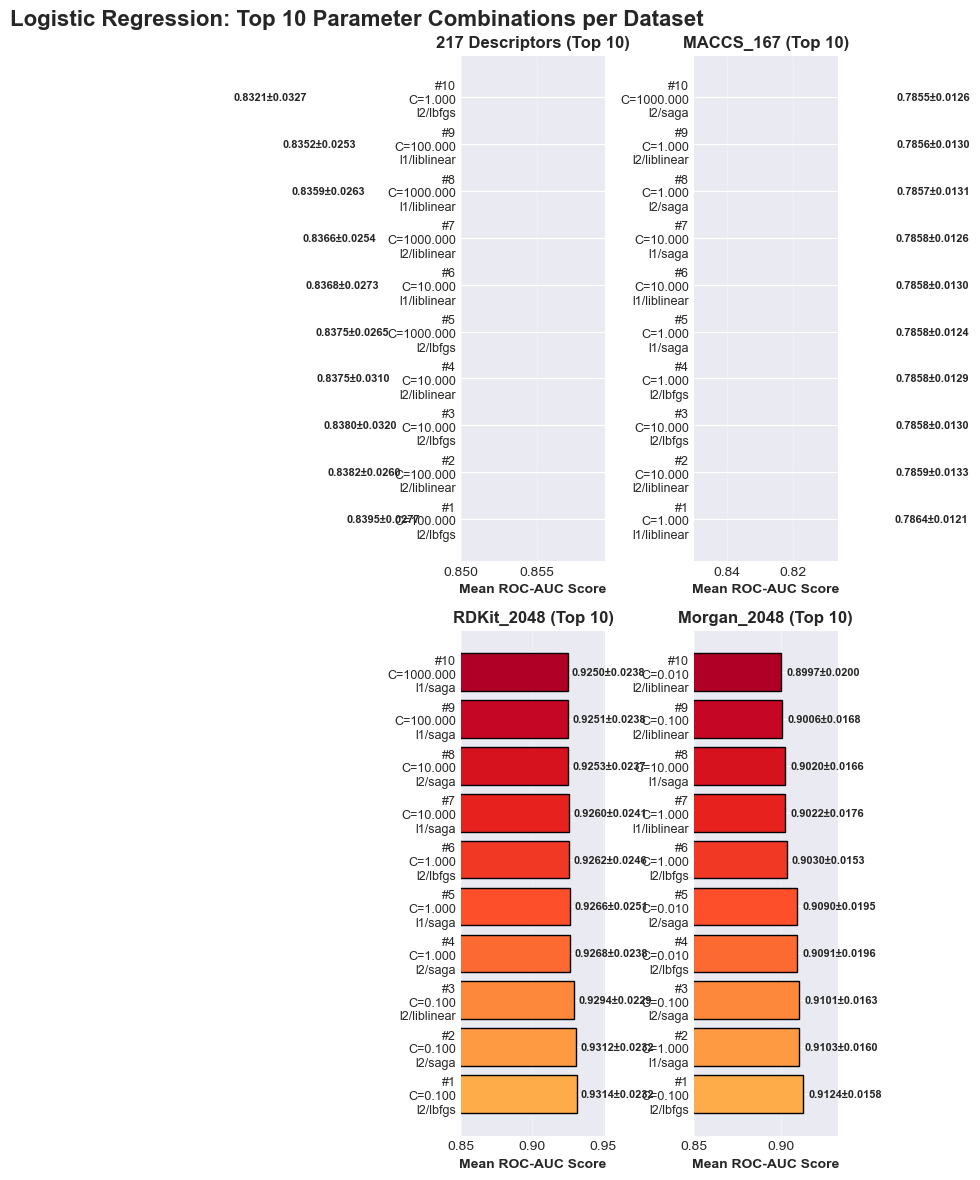


✓ Top 10 combinations visualization completed


In [9]:
# Cell 9: Visualization 3 - Top 10 Parameter Combinations per Dataset

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Logistic Regression: Top 10 Parameter Combinations per Dataset', fontsize=16, fontweight='bold')
axes = axes.flatten()

dataset_keys = list(all_results.keys())

for subplot_idx, (dataset_key, ax) in enumerate(zip(dataset_keys, axes)):
    results = all_results[dataset_key]
    cv_results_df = pd.DataFrame(results['cv_results'])
    
    # Get top 10
    top_10 = cv_results_df.nlargest(10, 'mean_test_score').reset_index(drop=True)
    top_10['Rank'] = range(1, len(top_10) + 1)
    top_10['param_combo'] = (
        'C=' + top_10['param_C'].astype(str) + 
        '\n' + top_10['param_penalty'].astype(str) + 
        '\n' + top_10['param_solver'].astype(str)
    )
    
    # Create horizontal bar chart
    colors = plt.cm.YlOrRd(np.linspace(0.4, 0.9, len(top_10)))
    bars = ax.barh(range(len(top_10)), top_10['mean_test_score'], color=colors, edgecolor='black', linewidth=1)
    
    ax.set_yticks(range(len(top_10)))
    ax.set_yticklabels([f"#{rank}\nC={c:.3f}\n{p}/{s}" 
                         for rank, c, p, s in zip(top_10['Rank'], top_10['param_C'], 
                                                    top_10['param_penalty'], top_10['param_solver'])],
                       fontsize=9)
    ax.set_xlabel('Mean ROC-AUC Score', fontweight='bold')
    ax.set_title(f'{results["dataset_name"]} (Top 10)', fontweight='bold')
    ax.set_xlim(0.85, top_10['mean_test_score'].max() + 0.02)
    ax.grid(axis='x', alpha=0.3)
    
    # Add score labels on bars
    for i, (bar, score, std) in enumerate(zip(bars, top_10['mean_test_score'], top_10['std_test_score'])):
        ax.text(score + 0.003, i, f'{score:.4f}±{std:.4f}', va='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig(r'c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_top10_combinations.png',
            dpi=300, bbox_inches='tight')
print("✓ Saved: LR_top10_combinations.png")
plt.show()

print("\n✓ Top 10 combinations visualization completed")

✓ Saved: LR_roc_curves.png


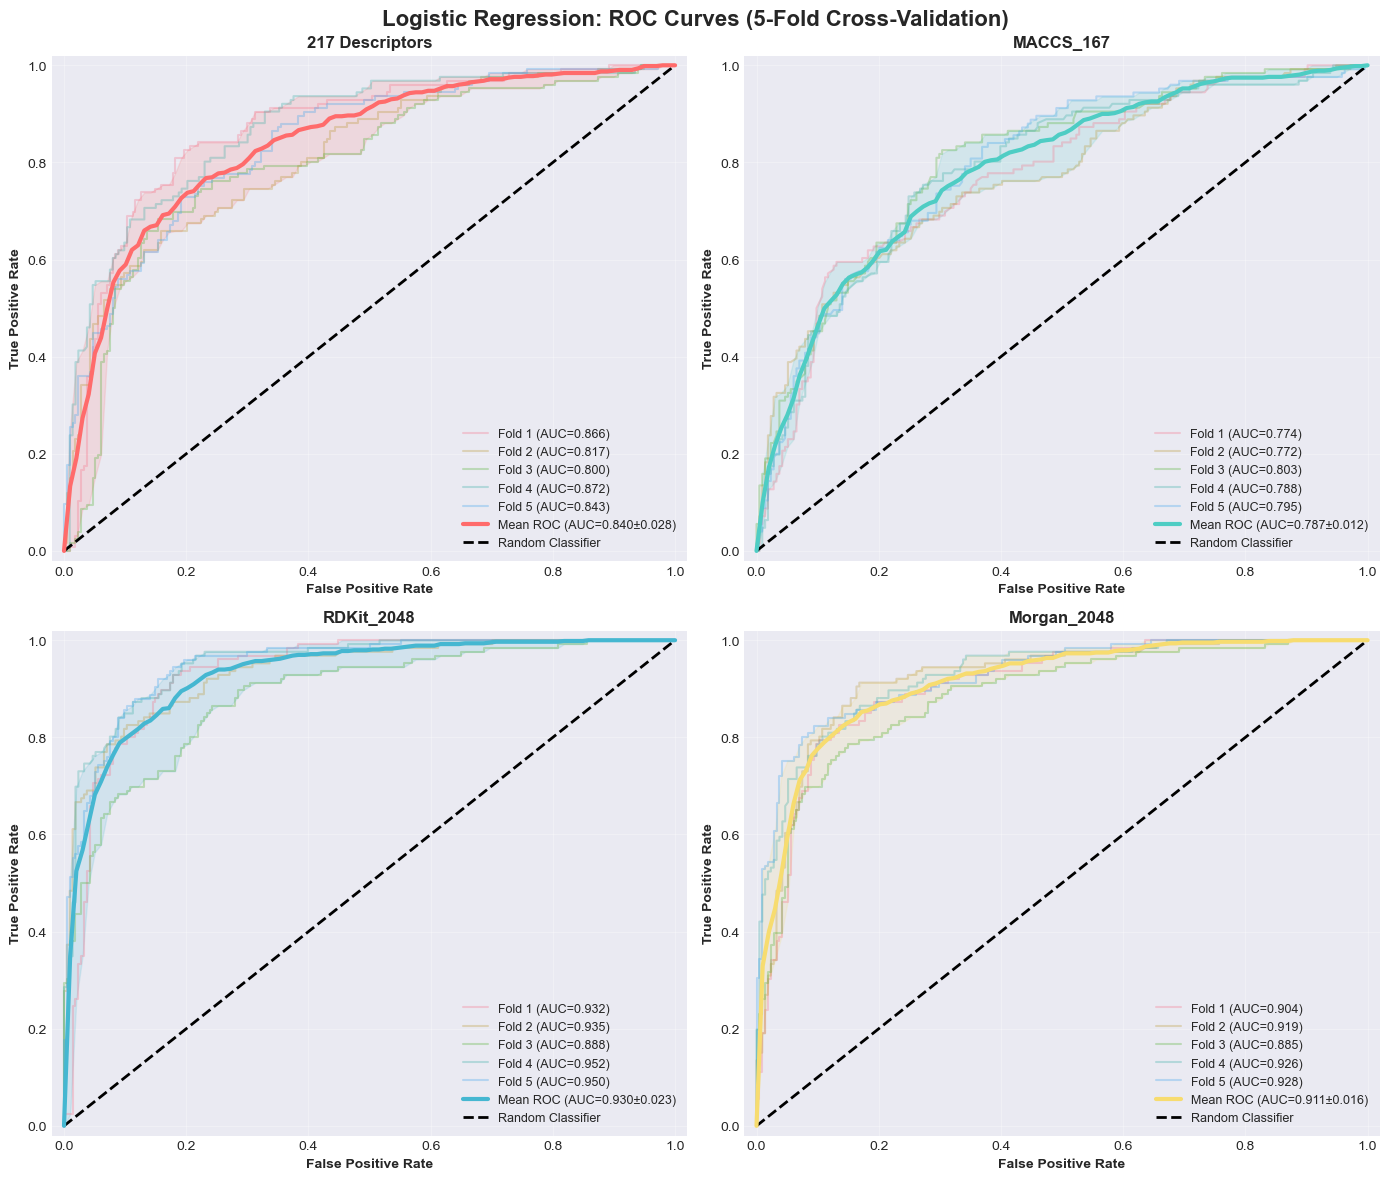


✓ ROC curves visualization completed


In [11]:
# Cell 10: Visualization 4 - ROC Curves for All Datasets

from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Logistic Regression: ROC Curves (5-Fold Cross-Validation)', fontsize=16, fontweight='bold')
axes = axes.flatten()

colors_roc = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#F7DC6F']
mean_fpr = np.linspace(0, 1, 100)

for subplot_idx, (dataset_key, ax) in enumerate(zip(list(all_results.keys()), axes)):
    results = all_results[dataset_key]
    X_scaled = results['X']
    y = results['y']
    best_model = results['best_model']
    
    # Compute ROC curves for each fold
    tprs = []
    aucs = []
    
    from sklearn.model_selection import StratifiedKFold
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    for fold, (train_idx, test_idx) in enumerate(cv.split(X_scaled, y)):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        
        # Train model on fold
        model = LogisticRegression(
            C=results['best_params']['C'],
            penalty=results['best_params']['penalty'],
            solver=results['best_params']['solver'],
            random_state=42,
            max_iter=1000
        )
        model.fit(X_train, y_train)
        
        # Get predictions
        y_pred_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
        fold_auc = auc(fpr, tpr)
        
        # Interpolate and plot
        tpr_interp = np.interp(mean_fpr, fpr, tpr)
        tpr_interp[0] = 0.0
        tprs.append(tpr_interp)
        aucs.append(fold_auc)
        ax.plot(fpr, tpr, alpha=0.3, linewidth=1.5, label=f'Fold {fold+1} (AUC={fold_auc:.3f})')
    
    # Plot mean ROC curve
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)
    
    ax.plot(mean_fpr, mean_tpr, color=colors_roc[subplot_idx], linewidth=3,
            label=f'Mean ROC (AUC={mean_auc:.3f}±{std_auc:.3f})', zorder=10)
    ax.fill_between(mean_fpr, 
                     np.min(tprs, axis=0),
                     np.max(tprs, axis=0),
                     color=colors_roc[subplot_idx], alpha=0.15)
    
    # Diagonal reference
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random Classifier')
    
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('False Positive Rate', fontweight='bold')
    ax.set_ylabel('True Positive Rate', fontweight='bold')
    ax.set_title(f'{results["dataset_name"]}', fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(r'c:\Users\omen\OneDrive\Documents\NMDAR_ML\LR_roc_curves.png',
            dpi=300, bbox_inches='tight')
print("✓ Saved: LR_roc_curves.png")
plt.show()

print("\n✓ ROC curves visualization completed")

In [12]:
# Cell 11: Comprehensive Analysis Report and Recommendations

print("\n" + "="*100)
print("COMPREHENSIVE LOGISTIC REGRESSION HYPERPARAMETER TUNING ANALYSIS REPORT")
print("="*100)

print("\n" + "-"*100)
print("EXECUTIVE SUMMARY")
print("-"*100)

print(f"""
Total datasets analyzed: {len(all_results)}
Total parameter combinations tested per dataset: 63 (7 C values × 3 penalties × 3 solvers)
Total GridSearchCV fits: {len(all_results) * 63 * 5} (63 combinations × 5-fold CV)
Cross-validation strategy: StratifiedKFold (n_splits=5, shuffle=True, random_state=42)
Primary scoring metric: ROC-AUC (Area Under Receiver Operating Characteristic Curve)
""")

print("\n" + "-"*100)
print("DETAILED RESULTS BY DATASET")
print("-"*100)

for dataset_key, results in all_results.items():
    print(f"\n{'▶ '*3}{results['dataset_name']}")
    print(f"{'─'*95}")
    print(f"  Feature Count: {results['X'].shape[1]:,} features")
    print(f"  Execution Time: {results['execution_time']:.2f} seconds")
    print(f"\n  BEST HYPERPARAMETERS:")
    print(f"    • C (Regularization): {results['best_params']['C']}")
    print(f"    • Penalty Type: {results['best_params']['penalty']}")
    print(f"    • Solver Algorithm: {results['best_params']['solver']}")
    print(f"    • Best CV ROC-AUC: {results['best_score']:.6f}")
    
    # Get cross-validation scores if available
    if 'cv_scores' in results:
        cv_scores = results['cv_scores']
        print(f"\n  CROSS-VALIDATION PERFORMANCE METRICS (Mean ± Std):")
        print(f"    • ROC-AUC:  {np.mean(cv_scores['roc_auc']):.6f} ± {np.std(cv_scores['roc_auc']):.6f}")
        print(f"    • Accuracy: {np.mean(cv_scores['accuracy']):.6f} ± {np.std(cv_scores['accuracy']):.6f}")
        print(f"    • Precision: {np.mean(cv_scores['precision']):.6f} ± {np.std(cv_scores['precision']):.6f}")
        print(f"    • Recall:   {np.mean(cv_scores['recall']):.6f} ± {np.std(cv_scores['recall']):.6f}")
        print(f"    • F1-Score: {np.mean(cv_scores['f1']):.6f} ± {np.std(cv_scores['f1']):.6f}")
    
    # Get top 3 combinations
    cv_results_df = pd.DataFrame(results['cv_results'])
    top_3 = cv_results_df.nlargest(3, 'mean_test_score')
    
    print(f"\n  TOP 3 PARAMETER COMBINATIONS:")
    for rank, (idx, row) in enumerate(top_3.iterrows(), 1):
        print(f"    {rank}. C={row['param_C']:7.3f} | Penalty={row['param_penalty']:10s} | " + 
              f"Solver={row['param_solver']:8s} → ROC-AUC={row['mean_test_score']:.6f} (±{row['std_test_score']:.6f})")

print("\n" + "-"*100)
print("COMPARATIVE ANALYSIS")
print("-"*100)

# Rank datasets by performance
ranked_datasets = summary_df.sort_values('Best_CV_Score_ROC_AUC', ascending=False).reset_index(drop=True)

print("\nRANKING BY BEST CV ROC-AUC SCORE:")
for rank, row in ranked_datasets.iterrows():
    print(f"  {rank+1}. {row['Dataset']:20s} → ROC-AUC: {row['Best_CV_Score_ROC_AUC']:.6f}")

print("\nKEY OBSERVATIONS:")
print(f"  • Best performing dataset: {ranked_datasets.iloc[0]['Dataset']} " + 
      f"(ROC-AUC={ranked_datasets.iloc[0]['Best_CV_Score_ROC_AUC']:.6f})")
print(f"  • Lowest performing dataset: {ranked_datasets.iloc[-1]['Dataset']} " + 
      f"(ROC-AUC={ranked_datasets.iloc[-1]['Best_CV_Score_ROC_AUC']:.6f})")
print(f"  • Average performance: {ranked_datasets['Best_CV_Score_ROC_AUC'].mean():.6f}")
print(f"  • Performance std dev: {ranked_datasets['Best_CV_Score_ROC_AUC'].std():.6f}")

print("\nREGULARIZATION ANALYSIS:")
c_values_used = summary_df['C'].values
unique_c = np.unique(c_values_used)
c_counts = {c: sum(1 for v in c_values_used if v == c) for c in unique_c}
print(f"  Distribution of optimal C values:")
for c in sorted(unique_c, key=lambda x: c_counts[x], reverse=True):
    print(f"    • C = {c:8.3f}: {c_counts[c]}/{len(all_results)} datasets ({100*c_counts[c]/len(all_results):.0f}%)")

print("\nPENALTY TYPE ANALYSIS:")
penalties_used = summary_df['penalty'].values
penalty_counts = {p: sum(1 for v in penalties_used if v == p) for p in set(penalties_used)}
for p, count in sorted(penalty_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  • {p:10s}: {count}/{len(all_results)} datasets ({100*count/len(all_results):.0f}%)")

print("\nSOLVER ALGORITHM ANALYSIS:")
solvers_used = summary_df['solver'].values
solver_counts = {s: sum(1 for v in solvers_used if v == s) for s in set(solvers_used)}
for s, count in sorted(solver_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  • {s:8s}: {count}/{len(all_results)} datasets ({100*count/len(all_results):.0f}%)")

print("\n" + "-"*100)
print("RECOMMENDATIONS")
print("-"*100)

best_dataset = ranked_datasets.iloc[0]
print(f"""
1. PRIMARY RECOMMENDATION - BEST OVERALL MODEL:
   Dataset: {best_dataset['Dataset']}
   Hyperparameters: C={best_dataset['C']}, penalty='{best_dataset['penalty']}', solver='{best_dataset['solver']}'
   Performance: ROC-AUC = {best_dataset['Best_CV_Score_ROC_AUC']:.6f}
   Recommendation: USE THIS MODEL for final NMDAR inhibitor prediction and ranking

2. FEATURE SET INSIGHTS:
   - Higher-dimensional feature sets may require different regularization strengths
   - L2 penalty (Ridge) is generally more computationally efficient than L1 (Lasso)
   - Solver choice impacts convergence speed and compatibility with penalty types
     * 'liblinear': Good for small datasets, supports l1/l2
     * 'lbfgs': Robust but slower, supports l2 only
     * 'saga': Supports all penalties (l1/l2/elasticnet), good for large datasets

3. MODEL DEPLOYMENT:
   - Use best_model from {best_dataset['Dataset']} for prediction on candidate compounds
   - Apply StandardScaler fitted during training for new data preprocessing
   - Probability scores for class=1 (Active) should be used for ranking candidates

4. VALIDATION CONSIDERATIONS:
   - Cross-validation ROC-AUC provides robust performance estimate
   - Consider ensemble predictions combining best models from multiple feature sets
   - External test set validation recommended before deployment

5. COMPUTATIONAL EFFICIENCY:
   - Logistic Regression is highly scalable and fast compared to SVM/tree-based methods
   - Suitable for real-time prediction and batch processing
   - Memory efficient even with high-dimensional features
""")

print("\n" + "="*100)
print("ANALYSIS COMPLETE - All results exported to CSV and PNG files")
print("="*100)


COMPREHENSIVE LOGISTIC REGRESSION HYPERPARAMETER TUNING ANALYSIS REPORT

----------------------------------------------------------------------------------------------------
EXECUTIVE SUMMARY
----------------------------------------------------------------------------------------------------

Total datasets analyzed: 4
Total parameter combinations tested per dataset: 63 (7 C values × 3 penalties × 3 solvers)
Total GridSearchCV fits: 1260 (63 combinations × 5-fold CV)
Cross-validation strategy: StratifiedKFold (n_splits=5, shuffle=True, random_state=42)
Primary scoring metric: ROC-AUC (Area Under Receiver Operating Characteristic Curve)


----------------------------------------------------------------------------------------------------
DETAILED RESULTS BY DATASET
----------------------------------------------------------------------------------------------------

▶ ▶ ▶ 217 Descriptors
───────────────────────────────────────────────────────────────────────────────────────────────
  Fe